In [1]:
import os, sys
import warnings
warnings.filterwarnings('ignore')
from IPython.display import display, Markdown, Math
import numpy as np
import pandas as pd
import networkx as nx
from scipy.stats import norm
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# Versión local de la librería: se busca src/pmule.py subiendo desde el directorio actual
_aqui = os.path.abspath('.')
while _aqui != os.path.dirname(_aqui) and not os.path.isfile(os.path.join(_aqui, 'src', 'pmule.py')):
    _aqui = os.path.dirname(_aqui)
sys.path.append(os.path.join(_aqui, 'src'))
from pmule import (PredecessorTable, ProjectGraph, EarnedValue,
                   pinta_tikz, plot_cargas, plot_curvas_valor_ganado,
                   tanto_por_uno, ordena_rutas)

In [2]:
%%capture
%mkdir -p ~/temp
%cd ~/temp

# Enunciado

Un compañero ha dibujado el grafo PERT que se muestra a continuación a partir del cuadro de prelaciones adjunto. Sospechamos que el grafo no refleja exactamente el cuadro.

In [3]:
#| tbl-cap: "Cuadro de prelaciones (correcto)"
#| label: tbl-datosEnunciado
datos_enunciado = pd.DataFrame([
#  activity, predecessor
    ('A'     , '---'      ),
    ('B'     , '---'      ),
    ('C'     , '---'      ),
    ('D'     , 'A,B,C'    ),
    ('E'     , 'D'        ),
    ('F'     , 'D'        ),
    ('G'     , 'E,F'      ),
    ('H'     , 'G'        ),
], columns=['activity', 'predecessor']).set_index('activity')
datos_enunciado

,predecessor
activity,
A,---
B,---
C,---
D,"A,B,C"
E,D
F,D
G,"E,F"
H,G


El proyecto corresponde a el lanzamiento de una aplicación móvil; las actividades son las siguientes (las duraciones del cuadro están en semanas).

In [4]:
#| tbl-cap: "Descripción de las actividades"
#| label: tbl-descripciones
descripciones = pd.Series({
    'A': 'Estudio de requisitos',
    'B': 'Diseño de la arquitectura',
    'C': 'Diseño de interfaz y prototipo',
    'D': 'Base de datos y modelo',
    'E': 'API del servidor',
    'F': 'Pantallas principales',
    'G': 'Módulo de pagos',
    'H': 'Notificaciones y sincronización',
}, name='Descripción')
descripciones.to_frame()

,Descripción
A,Estudio de requisitos
B,Diseño de la arquitectura
C,Diseño de interfaz y prototipo
D,Base de datos y modelo
E,API del servidor
F,Pantallas principales
G,Módulo de pagos
H,Notificaciones y sincronización


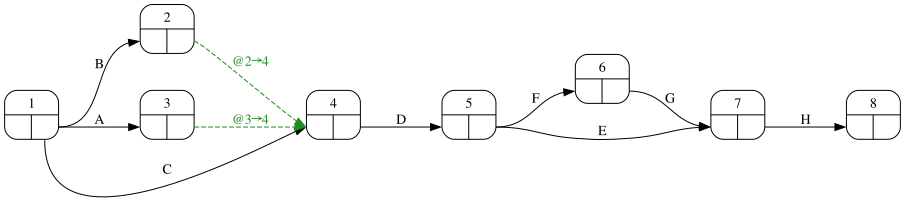

In [5]:
#| fig-cap: "Grafo PERT dibujado por el compañero"
#| label: fig-pertErroneo
prelaciones_del_grafo = {
    'A': '---',
    'B': '---',
    'C': '---',
    'D': 'A,B,C',
    'E': 'D',
    'F': 'D',
    'G': 'F',
    'H': 'E,G',
}
proyecto_dibujado = ProjectGraph.from_dict_of_strings(prelaciones_del_grafo)
proyecto_dibujado.pert(durations=False, ranksep=1)

In [6]:
pregunta_1 = "1. Construya el cuadro de ancestros a partir del cuadro de prelaciones y, por separado, a partir del grafo dibujado (siguiendo los arcos hacia atrás).  "
pregunta_2 = "2. Compare ambos cuadros e identifique qué prelaciones sobran y cuáles faltan en el grafo.  "
pregunta_3 = "3. Dibuje el grafo PERT correcto. ¿Cambia el número de ficticias?  "

for item in sorted(dir()):
    if item.startswith('pregunta_'):
        display(Markdown(eval(item)))

1. Construya el cuadro de ancestros a partir del cuadro de prelaciones y, por separado, a partir del grafo dibujado (siguiendo los arcos hacia atrás).  

2. Compare ambos cuadros e identifique qué prelaciones sobran y cuáles faltan en el grafo.  

3. Dibuje el grafo PERT correcto. ¿Cambia el número de ficticias?  

# Resolución

In [7]:
datos_proyecto = datos_enunciado.copy()
prelaciones = PredecessorTable.from_dataframe_of_strings(datos_proyecto, activity='activity', predecessor='predecessor')
proyecto = prelaciones.create_project()

## Apartado 1

In [8]:
display(Markdown(pregunta_1))

1. Construya el cuadro de ancestros a partir del cuadro de prelaciones y, por separado, a partir del grafo dibujado (siguiendo los arcos hacia atrás).  

In [9]:
#| tbl-cap: "Cuadro de ancestros según el cuadro de prelaciones"
#| label: tbl-ancestrosCuadro
proyecto.distant_predecessor(format='DataFrame')

,predecessors
A,----
B,----
C,----
D,"A, B, C"
E,"A, B, C, D"
F,"A, B, C, D"
G,"A, B, C, D, E, F"
H,"A, B, C, D, E, F, G"


In [10]:
#| tbl-cap: "Cuadro de ancestros según el grafo dibujado"
#| label: tbl-ancestrosGrafo
proyecto_dibujado.distant_predecessor(format='DataFrame')

,predecessors
A,----
B,----
C,----
D,"A, B, C"
E,"A, B, C, D"
F,"A, B, C, D"
G,"A, B, C, D, F"
H,"A, B, C, D, E, F, G"


## Apartado 2

In [11]:
display(Markdown(pregunta_2))

2. Compare ambos cuadros e identifique qué prelaciones sobran y cuáles faltan en el grafo.  

Una prelación que está en el cuadro y no en el grafo se detecta porque alguna actividad tiene menos ancestros en el grafo; una que sobra, porque tiene más. Para localizar la prelación inmediata responsable se comparan las predecesoras inmediatas de las actividades cuyo conjunto de ancestros difiere.

In [12]:
anc_cuadro = proyecto.distant_predecessor()
anc_grafo = proyecto_dibujado.distant_predecessor()
difieren = [a for a in datos_proyecto.index if anc_cuadro[a] != anc_grafo[a]]
pd.DataFrame({'ancestros según el cuadro': {a: ', '.join(sorted(anc_cuadro[a])) for a in difieren},
              'ancestros según el grafo': {a: ', '.join(sorted(anc_grafo[a])) for a in difieren}})

,ancestros según el cuadro,ancestros según el grafo
G,"A, B, C, D, E, F","A, B, C, D, F"


In [13]:
inm_cuadro = prelaciones.immediate_predecessor
inm_grafo = PredecessorTable.from_dict_of_strings(prelaciones_del_grafo).immediate_predecessor
faltan = sorted((p, a) for a in inm_cuadro for p in inm_cuadro[a] - inm_grafo.get(a, set()))
sobran = sorted((p, a) for a in inm_grafo for p in inm_grafo[a] - inm_cuadro.get(a, set()))
print('Faltan en el grafo:', faltan)
print('Sobran en el grafo:', sobran)

Faltan en el grafo: [('E', 'G')]
Sobran en el grafo: [('E', 'H')]


Las discrepancias son: falta la prelación E → G y sobra la prelación E → H (si la comparación muestra alguna más, es consecuencia de estas dos: al añadir o quitar una prelación cambian las que son redundantes).

## Apartado 3

In [14]:
display(Markdown(pregunta_3))

3. Dibuje el grafo PERT correcto. ¿Cambia el número de ficticias?  

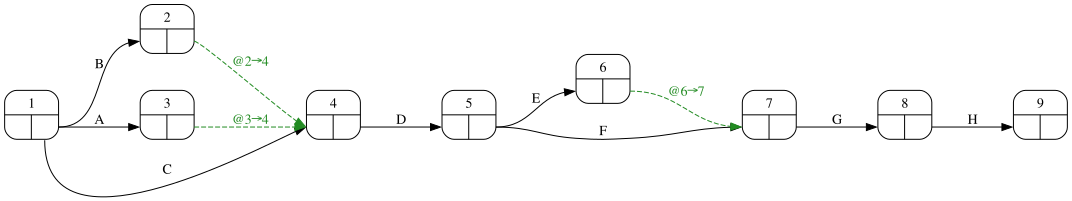

In [15]:
#| fig-cap: "Grafo PERT correcto"
#| label: fig-pertCorrecto
proyecto.pert(durations=False, ranksep=1)

In [16]:
Markdown(f'El grafo correcto tiene {len(proyecto.dummies)} ficticia(s) frente a {len(proyecto_dibujado.dummies)} del dibujado.')

El grafo correcto tiene 3 ficticia(s) frente a 2 del dibujado.